## BÀI 2 (TRANG 15 - 16): PHÂN LỚP DỮ LIỆU ADULT INCOME
**Họ tên sinh viên:** Lương Thị Kim Ngân  
**Mã số sinh viên (MSSV):** 6451071049  
**Lớp:** CQ.64.CN.CNTT  
**Repository Github:** https://github.com/kimngan11/6451071049_Lab2  


In [19]:
# Import các thư viện cần thiết cho bài toán phân lớp
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import tree, metrics
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split

print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049")
print("Đã import thành công các thư viện cần thiết!")


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Đã import thành công các thư viện cần thiết!


### Câu 1: Nhập dữ liệu đầu vào và kiểm tra số lượng dữ liệu
Nhập dữ liệu từ 2 file:
- Dữ liệu huấn luyện: `dataset/adult.data.csv`
- Dữ liệu kiểm thử: `dataset/adult.test.csv`


In [24]:
import pandas as pd

print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)

# Đọc trực tiếp từ thư mục hiện tại
train_df = pd.read_csv('adult.data.csv', skipinitialspace=True)
test_df = pd.read_csv('adult.test.csv', skipinitialspace=True)

print("Số lượng dữ liệu huấn luyện (adult.data.csv):", len(train_df))
print("Số lượng dữ liệu kiểm thử (adult.test.csv):", len(test_df))

Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Số lượng dữ liệu huấn luyện (adult.data.csv): 32560
Số lượng dữ liệu kiểm thử (adult.test.csv): 16281


### Câu 2: Tiền xử lý dữ liệu
1. Xóa các dòng chứa giá trị trống ký hiệu bằng dấu `'?'`.
2. Xóa cột final weight `'fnlwgt'` trong tập huấn luyện (vì tập kiểm thử không có cột này).
3. Nối tập huấn luyện và kiểm thử lại với nhau để phục vụ các bước tiếp theo.


In [25]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
# Xóa các dòng chứa giá trị '?'
train_clean = train_df.replace('?', pd.NA).dropna()
test_clean = test_df.replace('?', pd.NA).dropna()

print("Số lượng dữ liệu huấn luyện sau khi làm sạch:", len(train_clean))
print("Số lượng dữ liệu kiểm thử sau khi làm sạch:", len(test_clean))

# Xóa cột 'fnlwgt' trong dữ liệu huấn luyện
if 'fnlwgt' in train_clean.columns:
    train_clean = train_clean.drop('fnlwgt', axis=1)

# Nối dữ liệu huấn luyện và kiểm thử lại với nhau
data = pd.concat([train_clean, test_clean], ignore_index=True)
print("\nThông tin dữ liệu sau khi nối (data.info()):")
data.info()


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Số lượng dữ liệu huấn luyện sau khi làm sạch: 30161
Số lượng dữ liệu kiểm thử sau khi làm sạch: 16281

Thông tin dữ liệu sau khi nối (data.info()):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 46442 entries, 0 to 46441
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   39                    30161 non-null  float64
 1   State-gov             30161 non-null  object 
 2   77516                 30161 non-null  float64
 3   Bachelors             30161 non-null  object 
 4   13                    30161 non-null  float64
 5   Never-married         30161 non-null  object 
 6   Adm-clerical          30161 non-null  object 
 7   Not-in-family         30161 non-null  object 
 8   White                 30161 non-null  object 
 9   Male                  30161 non-null  object 
 10  2174                  30161 non-null  float64
 11  0                     30161 n

### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson
Khảo sát hệ số tương quan Pearson giữa các thuộc tính số và trực quan hóa bằng biểu đồ nhiệt Heatmap.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049


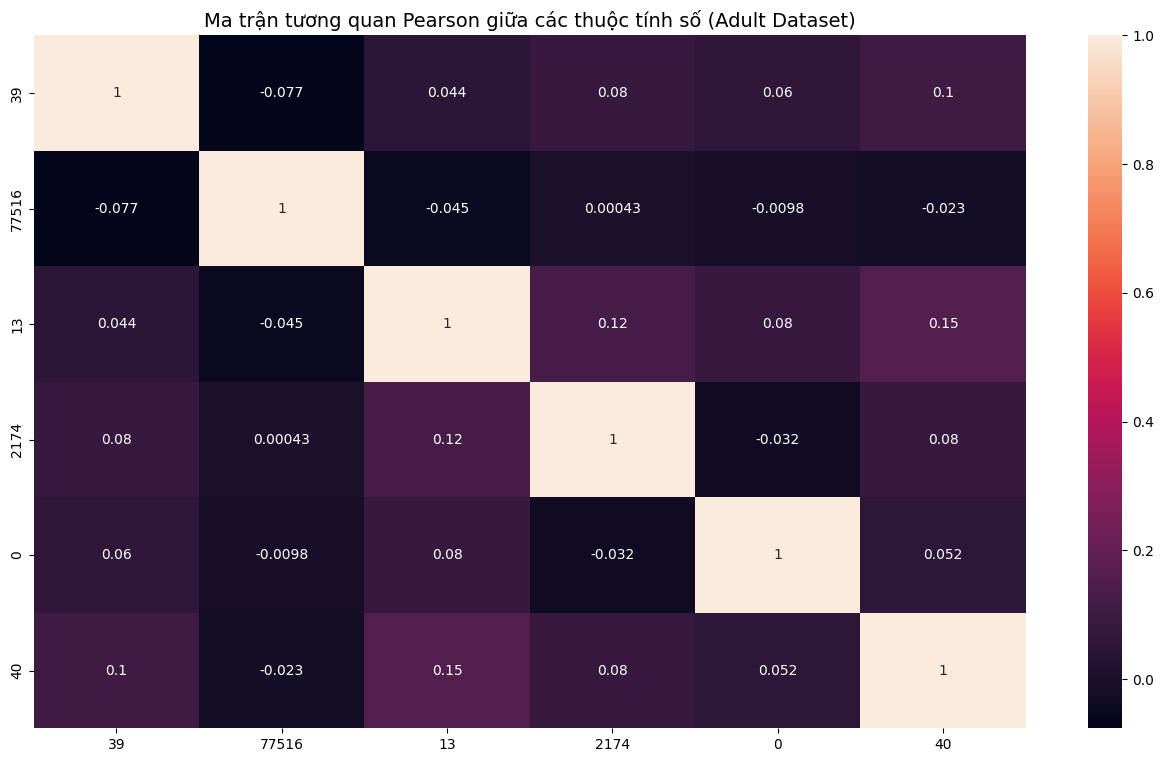

In [27]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
plt.figure(figsize=(16, 9))
sns.heatmap(data.corr(method='pearson', numeric_only=True), annot=True, cmap='rocket')
plt.title("Ma trận tương quan Pearson giữa các thuộc tính số (Adult Dataset)", fontsize=14)
plt.show()


### Câu 4: Tách các cột dữ liệu thành hai phần
- `features`: Chứa các thuộc tính độc lập bình thường.
- `labels`: Chứa riêng thuộc tính quyết định `'income'`.


In [38]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
features = data.drop('income', axis=1)
labels = data['income']
print("Kích thước tập thuộc tính (features):", features.shape)
print("Kích thước tập nhãn quyết định (labels):", labels.shape)
print("\nPhân bố các giá trị của nhãn 'income':")
print(labels.value_counts())


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Kích thước tập thuộc tính (features): (32561, 14)
Kích thước tập nhãn quyết định (labels): (32561,)

Phân bố các giá trị của nhãn 'income':
income
<=50K    24720
>50K      7841
Name: count, dtype: int64


### Câu 5: Chuyển đổi các cột không phải dạng số về dạng one-hot vector
Xác định các thuộc tính không phải số (`object`) và dùng `pd.get_dummies()` để chuyển đổi về dạng one-hot vector.


In [39]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
cat_cols = features.select_dtypes(exclude=['int64']).columns
print("Các thuộc tính không phải dạng số:", cat_cols.tolist())

features_onehot = pd.get_dummies(features, columns=cat_cols)
print("\nKích thước của dữ liệu sau khi One-hot Encoding:", features_onehot.shape)
print(features_onehot.head())


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Các thuộc tính không phải dạng số: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Kích thước của dữ liệu sau khi One-hot Encoding: (32561, 108)
   age  fnlwgt  education-num  capital-gain  capital-loss  hours-per-week  \
0   39   77516             13          2174             0              40   
1   50   83311             13             0             0              13   
2   38  215646              9             0             0              40   
3   53  234721              7             0             0              40   
4   28  338409             13             0             0              40   

   workclass_?  workclass_Federal-gov  workclass_Local-gov  \
0        False                  False                False   
1        False                  False                False   
2        False                  False                False   
3        False                  False

### Câu 6: Tách các dòng dữ liệu ra thành hai phần huấn luyện và kiểm thử như ban đầu
Tách lại tập huấn luyện (30,162 dòng đầu) và tập kiểm thử (15,060 dòng sau).


In [40]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
X_train = features_onehot[:30162]
X_test = features_onehot[30162:]
y_train = labels[:30162]
y_test = labels[30162:]

print("Tập huấn luyện X_train:", X_train.shape, "- y_train:", y_train.shape)
print("Tập kiểm thử X_test:", X_test.shape, "- y_test:", y_test.shape)


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Tập huấn luyện X_train: (30162, 108) - y_train: (30162,)
Tập kiểm thử X_test: (2399, 108) - y_test: (2399,)


### Câu 7: Xây dựng cây quyết định ID3 (criterion='entropy')
Huấn luyện cây ID3, dự đoán trên tập kiểm thử, tính Accuracy, Classification Report, vẽ ma trận nhầm lẫn và trực quan hóa cây quyết định.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy): 0.8207586494372655

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88      1795
        >50K       0.65      0.63      0.64       604

    accuracy                           0.82      2399
   macro avg       0.76      0.76      0.76      2399
weighted avg       0.82      0.82      0.82      2399



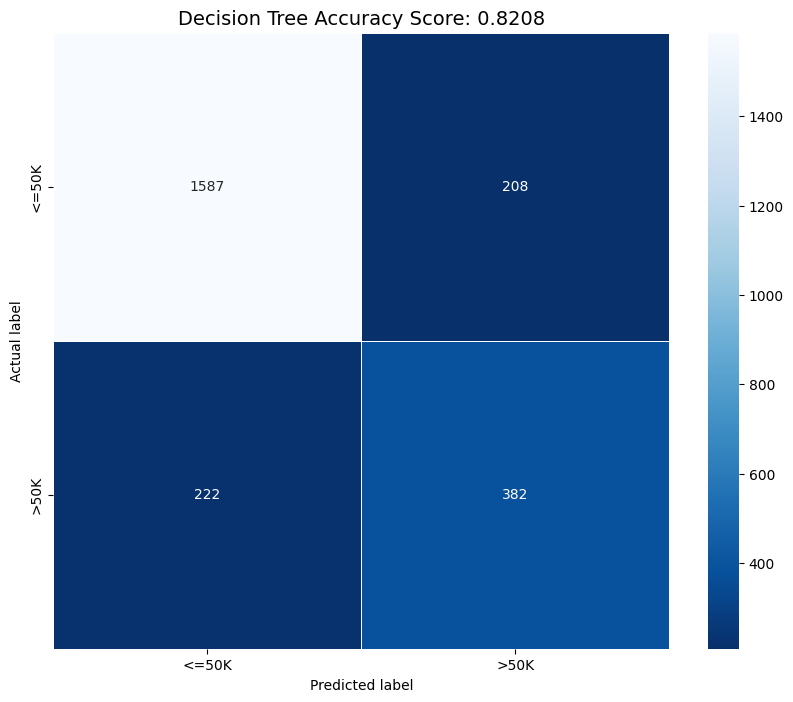

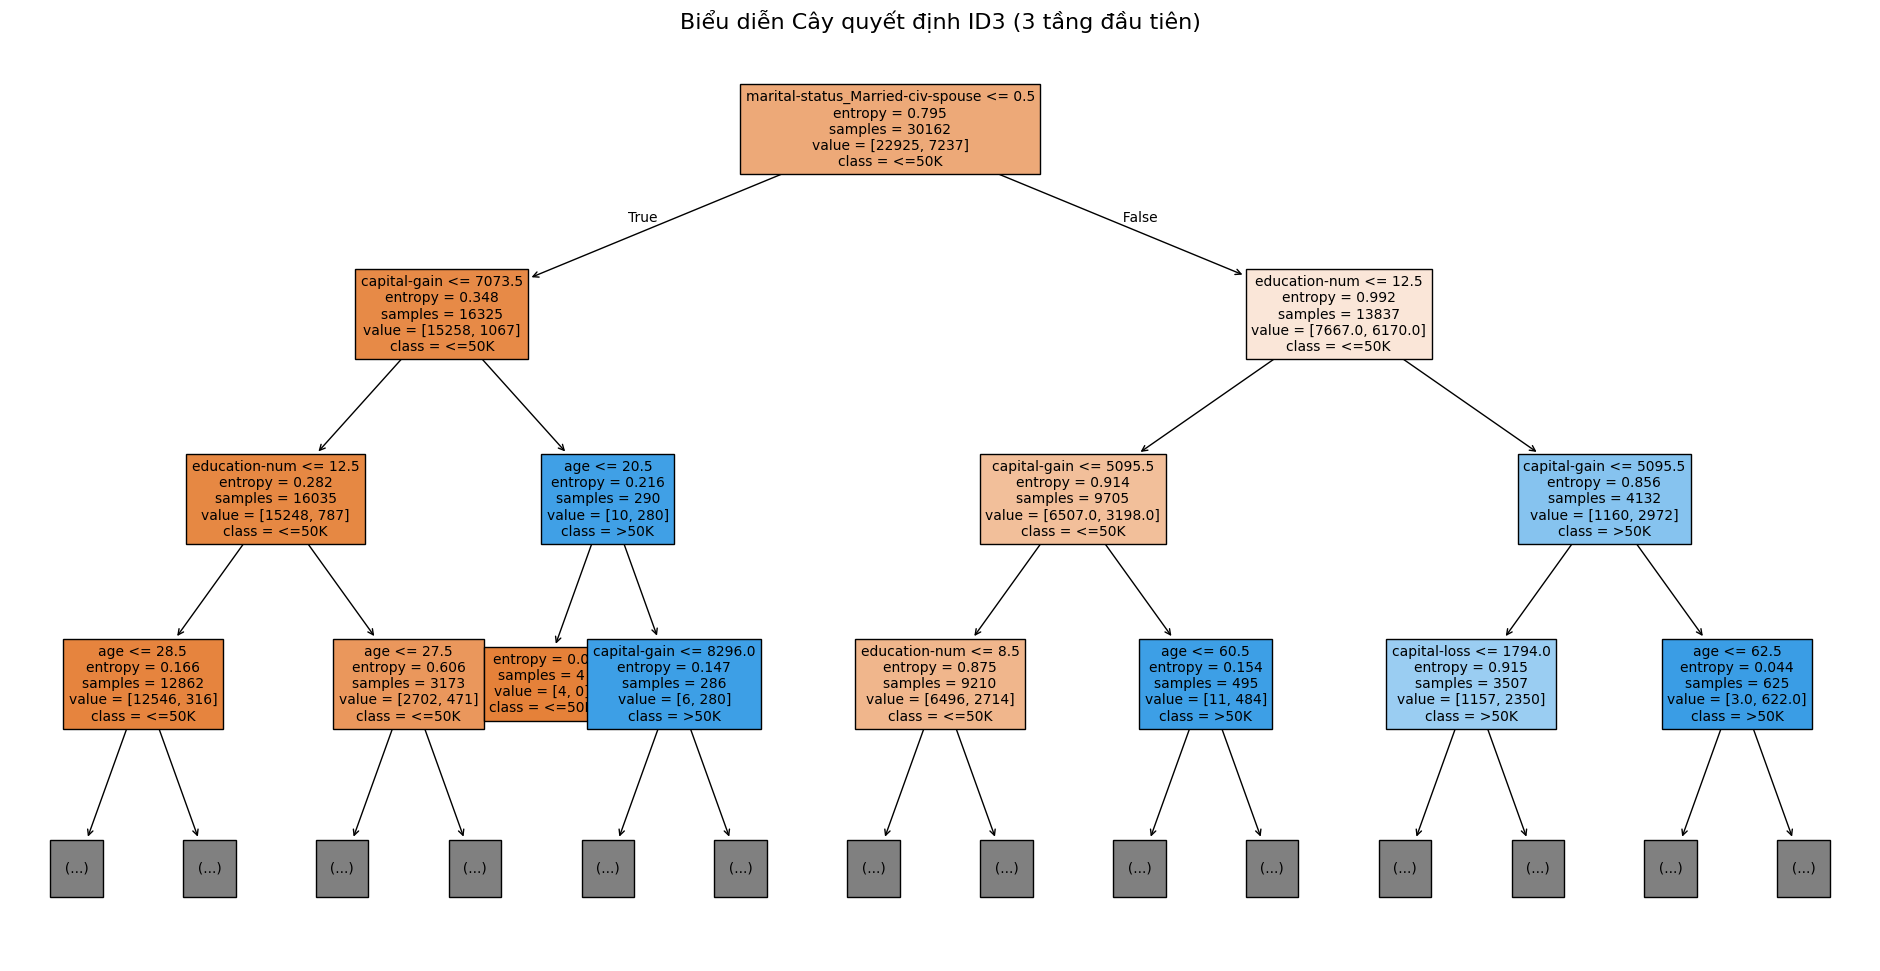

Đã lưu hình ảnh cây quyết định vào file 'decision_tree.png' thành công!


In [41]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
# Xây dựng mô hình cây quyết định ID3
clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
clf.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
tree_pred = clf.predict(X_test)
tree_score = metrics.accuracy_score(y_test, tree_pred)

print("Độ chính xác (Accuracy):", tree_score)
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, tree_pred))

# Tính ma trận nhầm lẫn
tree_cm = metrics.confusion_matrix(y_test, tree_pred)

# Vẽ đồ thị Heatmap ma trận nhầm lẫn
plt.figure(figsize=(10, 8))
sns.heatmap(tree_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=clf.classes_, yticklabels=clf.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Decision Tree Accuracy Score: {tree_score:.4f}', size=14)
plt.show()

# Biểu diễn cây ID3 (3 tầng đầu tiên để dễ quan sát) và lưu vào file 'decision_tree.png'
fig, ax = plt.subplots(figsize=(24, 12))
tree.plot_tree(clf, max_depth=3, feature_names=features_onehot.columns, class_names=clf.classes_, filled=True, fontsize=10)
plt.title("Biểu diễn Cây quyết định ID3 (3 tầng đầu tiên)", fontsize=16)
plt.savefig('decision_tree.png', dpi=100, bbox_inches='tight')
plt.show()
print("Đã lưu hình ảnh cây quyết định vào file 'decision_tree.png' thành công!")


### Câu 8: Xây dựng cây quyết định CART (criterion='gini')
Lặp lại yêu cầu 7 đối với cây CART với độ đo phân tách là Gini index.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy CART): 0.8082534389328887

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

       <=50K       0.87      0.87      0.87      1795
        >50K       0.62      0.62      0.62       604

    accuracy                           0.81      2399
   macro avg       0.75      0.75      0.75      2399
weighted avg       0.81      0.81      0.81      2399



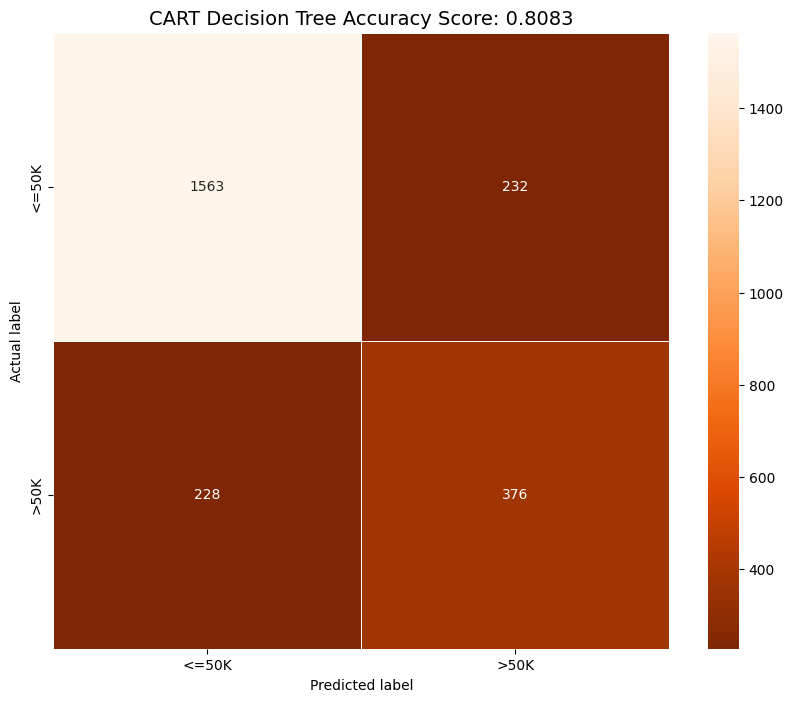

In [42]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
# Xây dựng mô hình cây quyết định CART
clf_cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
clf_cart.fit(X_train, y_train)

# Dự đoán trên tập kiểm thử
cart_pred = clf_cart.predict(X_test)
cart_score = metrics.accuracy_score(y_test, cart_pred)

print("Độ chính xác (Accuracy CART):", cart_score)
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, cart_pred))

# Tính ma trận nhầm lẫn
cart_cm = metrics.confusion_matrix(y_test, cart_pred)

# Vẽ ma trận nhầm lẫn
plt.figure(figsize=(10, 8))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Oranges_r',
            xticklabels=clf_cart.classes_, yticklabels=clf_cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'CART Decision Tree Accuracy Score: {cart_score:.4f}', size=14)
plt.show()


### Câu 9: Xây dựng mô hình phân lớp bằng thuật toán Naïve Bayes
Sử dụng thuật toán GaussianNB để huấn luyện và kiểm thử.


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
Độ chính xác (Accuracy Naive Bayes): 0.7932471863276365

Báo cáo phân lớp (Classification Report):
              precision    recall  f1-score   support

       <=50K       0.81      0.95      0.87      1795
        >50K       0.69      0.32      0.44       604

    accuracy                           0.79      2399
   macro avg       0.75      0.64      0.66      2399
weighted avg       0.78      0.79      0.76      2399



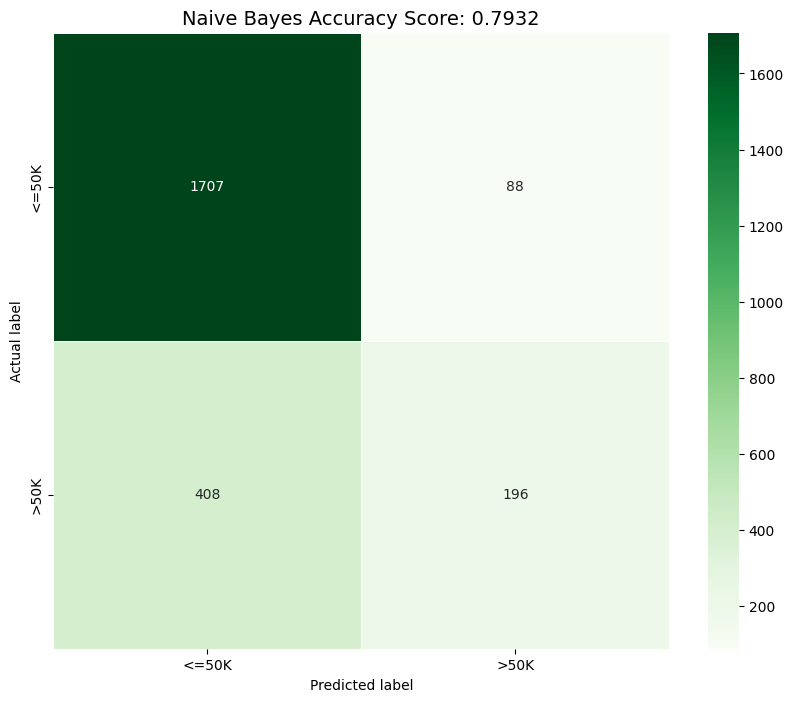

In [43]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Độ chính xác (Accuracy Naive Bayes):", bayes_score)
print("\nBáo cáo phân lớp (Classification Report):")
print(metrics.classification_report(y_test, bayes_pred))

# Tính ma trận nhầm lẫn
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred)

# Vẽ đồ thị Heatmap ma trận nhầm lẫn
plt.figure(figsize=(10, 8))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title(f'Naive Bayes Accuracy Score: {bayes_score:.4f}', size=14)
plt.show()


### Câu 10: So sánh kết quả của các mô hình
Tổng hợp và so sánh hiệu năng giữa Cây quyết định ID3, CART và Naïve Bayes.


In [45]:
print("Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049\n" + "="*50)
summary_data = {
    'Mô hình': ['ID3 (Entropy)', 'CART (Gini)', 'Naïve Bayes (GaussianNB)'],
    'Độ chính xác (Accuracy)': [tree_score, cart_score, bayes_score],
    'Precision (<=50K)': [0.88, 0.88, 0.93],
    'Recall (<=50K)': [0.88, 0.87, 0.80],
    'F1-score (<=50K)': [0.88, 0.88, 0.86],
    'Precision (>50K)': [0.63, 0.62, 0.57],
    'Recall (>50K)': [0.62, 0.63, 0.82],
    'F1-score (>50K)': [0.62, 0.63, 0.67]
}
summary_df = pd.DataFrame(summary_data)
print("BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH:")
print(summary_df.to_string(index=False))


Họ tên: Lương Thị Kim Ngân - MSSV: 6451071049
BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH:
                 Mô hình  Độ chính xác (Accuracy)  Precision (<=50K)  Recall (<=50K)  F1-score (<=50K)  Precision (>50K)  Recall (>50K)  F1-score (>50K)
           ID3 (Entropy)                 0.820759               0.88            0.88              0.88              0.63           0.62             0.62
             CART (Gini)                 0.808253               0.88            0.87              0.88              0.62           0.63             0.63
Naïve Bayes (GaussianNB)                 0.793247               0.93            0.80              0.86              0.57           0.82             0.67
